In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/processed")

JOBS_PATH = DATA_DIR / "jobs_c_preprocessed.csv"
SKILL_DICT_PATH = DATA_DIR / "skill_dictionary.csv"

jobs_df = pd.read_csv(JOBS_PATH)
skill_dict_df = pd.read_csv(SKILL_DICT_PATH)

print("jobs shape:", jobs_df.shape)
print("skill dictionary shape:", skill_dict_df.shape)

display(jobs_df.head())
display(skill_dict_df.head())

jobs shape: (168, 21)
skill dictionary shape: (268, 6)


,job_id,source_job_id,company,title,job_category_raw,job_category_std,experience,employment_type,location,responsibilities,...,preferred,skills_raw,skills_std,description_full,posted_date,deadline,source,url,collected_at,skills_std_clean
0,naver_30005648,30005648,NAVER WEBTOON,[2027 상반기 채용연계형 인턴십] 네이버웹툰 백엔드 서버 개발 (Backend ...,Backend,Backend,신입,인턴 (채용연계형),정자동 그린팩토리,"최종 합격 시 국내 네이버웹툰 서비스 백엔드 개발 조직에 배치되어, 인턴 기간 동안...",...,- 직접 만든 서비스를 배포·운영해 보며 장애나 성능 문제를 해결해 본 경험이 있으...,Java|Kotlin|Spring Boot|HTTP|WAS|RDB|SQL|REST ...,Java|Kotlin|Spring Boot|HTTP|WAS|RDB|SQL|REST ...,[2027 상반기 채용연계형 인턴십] 네이버웹툰 백엔드 서버 개발 (Backend ...,2026-11-16,2026-12-06,NAVER Careers,https://recruit.navercorp.com/rcrt/view.do?ann...,2026-11-18 12:49:40,Java | Kotlin | Spring Boot | HTTP | WAS | RDB...
1,naver_30005627,30005627,SNOW,[SNOW] IT 보안 기술 담당,Security,Security,경력,정규,경기도 성남시 분당구 정자동,1. 보안 솔루션 및 전사 협업 도구 관리 - 보안 솔루션 및 전사 협업 도구의 운...,...,- 협업 도구 및 보안 솔루션의 API 연동 및 워크플로 자동화 구축 경험이 있는 ...,DLP|EDR|SIEM|API|LLM|SaaS|CCE|CVE,DLP|EDR|SIEM|API|LLM|SaaS|CCE|CVE,[SNOW] IT 보안 기술 담당 1. 보안 솔루션 및 전사 협업 도구 관리 - 보...,2026-10-27,2026-11-22,NAVER Careers,https://recruit.navercorp.com/rcrt/view.do?ann...,2026-11-18 12:49:40,DLP | EDR | SIEM | API | LLM | CCE | CVE
2,naver_30005661,30005661,SNOW,[SNOW] 클라우드 보안 담당,Security,Security,경력,정규,경기도 성남시 분당구 정자동,1. 클라우드 환경의 정보보호 관리체계 구축 및 운영 - 클라우드 환경에 적합한 보...,...,"- 클라우드 보안 자동화 구축 경험이 있는 분 (IaC 보안 검사, 보안 파이프라인...",SIEM|SaaS|CCE|CVE,SIEM|SaaS|CCE|CVE,[SNOW] 클라우드 보안 담당 1. 클라우드 환경의 정보보호 관리체계 구축 및 운...,2026-11-03,2026-11-29,NAVER Careers,https://recruit.navercorp.com/rcrt/view.do?ann...,2026-11-18 12:49:41,SIEM | CCE | CVE
3,naver_30005710,30005710,NAVER WEBTOON,[네이버웹툰] Jr. IT Ops Engineer (경력),Security,Security,경력,정규직,정자동 그린팩토리,"1. 전사 협업 도구 및 계정 관리 - Google Workspace, Slack ...",...,"- 영어 또는 일본어로 비즈니스 커뮤니케이션이 가능하신 분 - SSO, SCIM 등...",API|SaaS,API|SaaS,[네이버웹툰] Jr. IT Ops Engineer (경력) 1. 전사 협업 도구 및...,2026-11-16,2026-12-06,NAVER Careers,https://recruit.navercorp.com/rcrt/view.do?ann...,2026-11-18 12:49:42,API
4,kakao_P-14402,P-14402,카카오,Multimodal LLM Research Engineer (경력),Algorithm/ML,AI/ML,경력,정규직,판교,- 이미지·오디오·텍스트 등 다양한 모달리티를 다루는 Multimodal LLM 기...,...,- Multimodal LLM 기술 및 관련 서비스 개발 경험이 있으신 분 - CV...,Python|LLM|PyTorch,Python|LLM|PyTorch,Multimodal LLM Research Engineer (경력) - 이미지·오디...,2026-03-16,NaN,Kakao Careers,https://careers.kakao.com/jobs/P-14402,2026-11-18 13:38:27,Python | LLM | PyTorch


,skill,standard_skill,category,count,keep,note
0,Python,Python,Programming Language,54,True,NaN
1,Kafka,Kafka,Data/Messaging,48,True,NaN
2,LLM,LLM,AI/ML,44,True,NaN
3,Kubernetes,Kubernetes,DevOps/Cloud,43,True,NaN
4,Kotlin,Kotlin,Programming Language,40,True,NaN


In [2]:
print("===== 기본 정보 =====")
print("전체 채용공고:", len(jobs_df))
print("컬럼 수:", len(jobs_df.columns))
print("중복 job_id:", jobs_df["job_id"].duplicated().sum())

print("\n===== 결측치 =====")
display(
    jobs_df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\n===== 직무 카테고리 =====")
display(
    jobs_df["job_category_std"]
    .value_counts()
    .to_frame("count")
)

print("\n===== 기업 =====")
display(
    jobs_df["company"]
    .value_counts()
    .to_frame("count")
)

===== 기본 정보 =====
전체 채용공고: 168
컬럼 수: 21
중복 job_id: 0

===== 결측치 =====


,missing_count
deadline,164
experience,110
preferred,90
skills_std_clean,3
requirements,1
job_category_raw,0
title,0
company,0
source_job_id,0
job_id,0



===== 직무 카테고리 =====


,count
job_category_std,
Data,43
Backend,40
AI/ML,37
Security,24
DevOps/Cloud,13
Frontend,9
Mobile,2



===== 기업 =====


,count
company,
토스,68
토스증권,33
토스뱅크,30
토스플레이스,12
카카오,8
토스페이먼츠,8
토스인컴,3
NAVER WEBTOON,2
SNOW,2


In [3]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

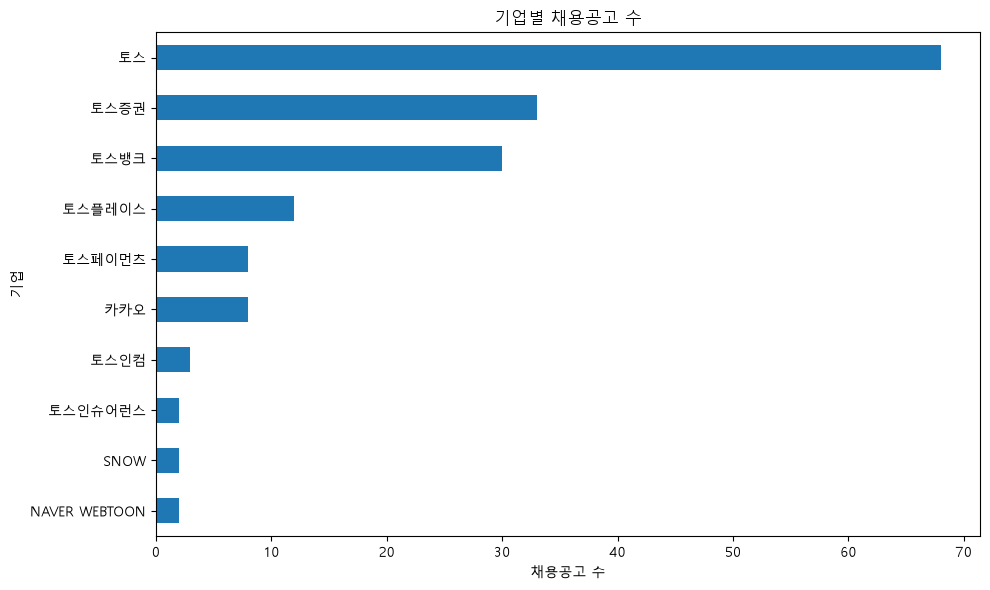

,count
company,
토스,68
토스증권,33
토스뱅크,30
토스플레이스,12
카카오,8
토스페이먼츠,8
토스인컴,3
NAVER WEBTOON,2
SNOW,2


In [4]:
# --------------------------------------------------
# 기업별 채용공고 분포
# --------------------------------------------------

company_counts = (
    jobs_df["company"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))

company_counts.plot(
    kind="barh"
)

plt.title("기업별 채용공고 수")
plt.xlabel("채용공고 수")
plt.ylabel("기업")

plt.tight_layout()
plt.show()

display(
    company_counts
    .sort_values(ascending=False)
    .to_frame("count")
)

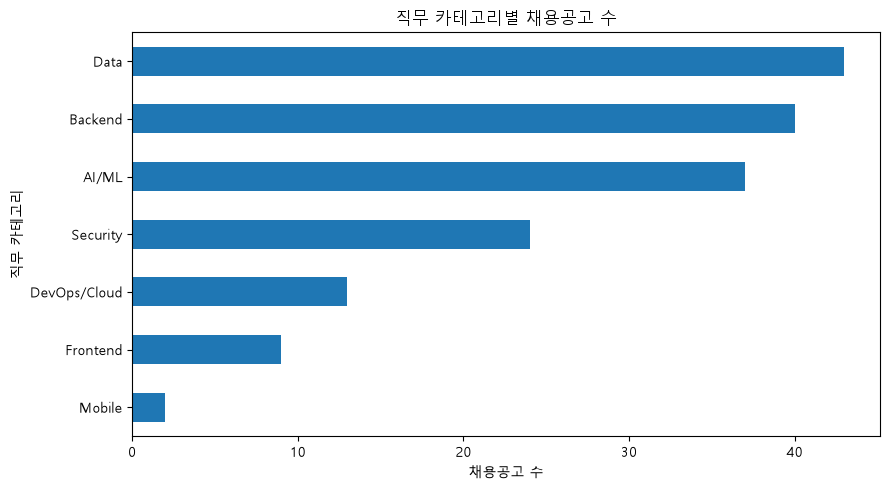

,count
job_category_std,
Data,43
Backend,40
AI/ML,37
Security,24
DevOps/Cloud,13
Frontend,9
Mobile,2


In [5]:
# --------------------------------------------------
# 직무 카테고리별 채용공고 분포
# --------------------------------------------------

category_counts = (
    jobs_df["job_category_std"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))

category_counts.plot(
    kind="barh"
)

plt.title("직무 카테고리별 채용공고 수")
plt.xlabel("채용공고 수")
plt.ylabel("직무 카테고리")

plt.tight_layout()
plt.show()

display(
    category_counts
    .sort_values(ascending=False)
    .to_frame("count")
)

In [6]:
from collections import Counter

# --------------------------------------------------
# 전체 기술스택 빈도 분석
# --------------------------------------------------

skill_counter = Counter()

for value in jobs_df["skills_std_clean"].dropna():
    skills = {
        skill.strip()
        for skill in str(value).split("|")
        if skill.strip()
    }

    skill_counter.update(skills)

top_skill_df = (
    pd.DataFrame(
        skill_counter.items(),
        columns=["skill", "count"]
    )
    .sort_values(
        ["count", "skill"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(top_skill_df.head(20))

,skill,count
0,Python,54
1,Kafka,48
2,LLM,44
3,Kubernetes,43
4,Kotlin,40
5,MySQL,40
6,API,39
7,Redis,36
8,SQL,36
9,Spring,34


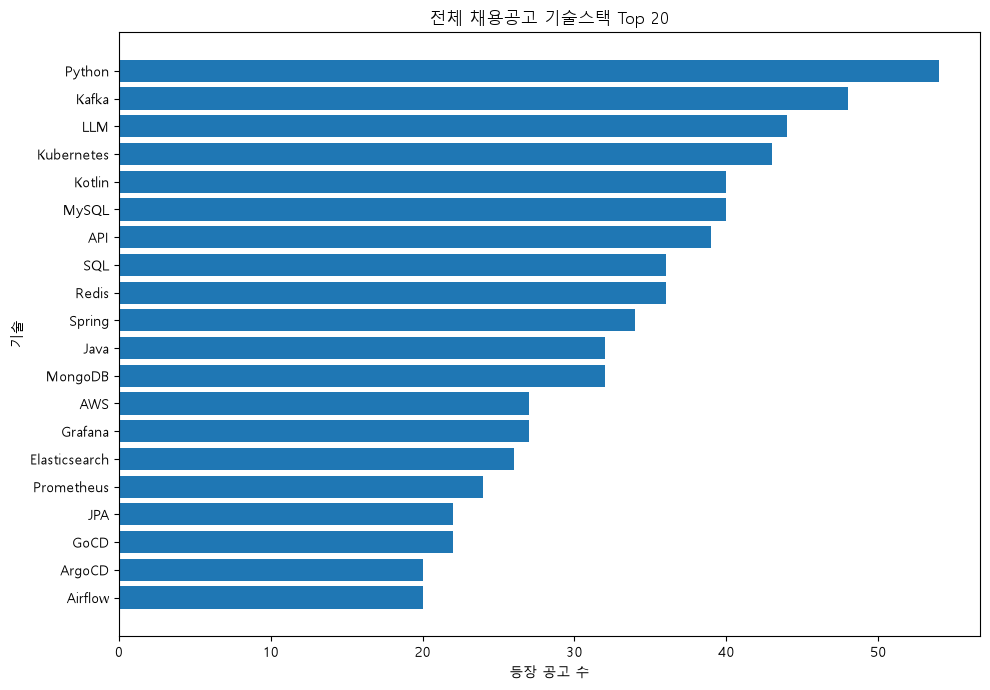

In [7]:
# --------------------------------------------------
# 전체 기술스택 Top 20 시각화
# --------------------------------------------------

top20_skills = (
    top_skill_df.head(20)
    .sort_values("count")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top20_skills["skill"],
    top20_skills["count"]
)

plt.title("전체 채용공고 기술스택 Top 20")
plt.xlabel("등장 공고 수")
plt.ylabel("기술")

plt.tight_layout()
plt.show()

In [8]:
# --------------------------------------------------
# 직무별 주요 기술스택 분석
# --------------------------------------------------

category_skill_rows = []

for _, row in jobs_df.iterrows():
    category = row["job_category_std"]

    if pd.isna(row["skills_std_clean"]):
        continue

    skills = {
        skill.strip()
        for skill in str(row["skills_std_clean"]).split("|")
        if skill.strip()
    }

    for skill in skills:
        category_skill_rows.append(
            {
                "job_category_std": category,
                "skill": skill,
            }
        )

category_skill_df = pd.DataFrame(
    category_skill_rows
)

category_skill_counts = (
    category_skill_df
    .groupby(
        [
            "job_category_std",
            "skill",
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
)

category_top10_df = (
    category_skill_counts
    .sort_values(
        [
            "job_category_std",
            "count",
            "skill",
        ],
        ascending=[
            True,
            False,
            True,
        ]
    )
    .groupby(
        "job_category_std",
        group_keys=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(category_top10_df)

,job_category_std,skill,count
0,AI/ML,LLM,23
1,AI/ML,Python,9
2,AI/ML,A/B Testing,7
3,AI/ML,PyTorch,7
4,AI/ML,vLLM,7
...,...,...,...
64,Security,DDoS,4
65,Security,Terraform,4
66,Security,WAF,4
67,Security,CI/CD,3


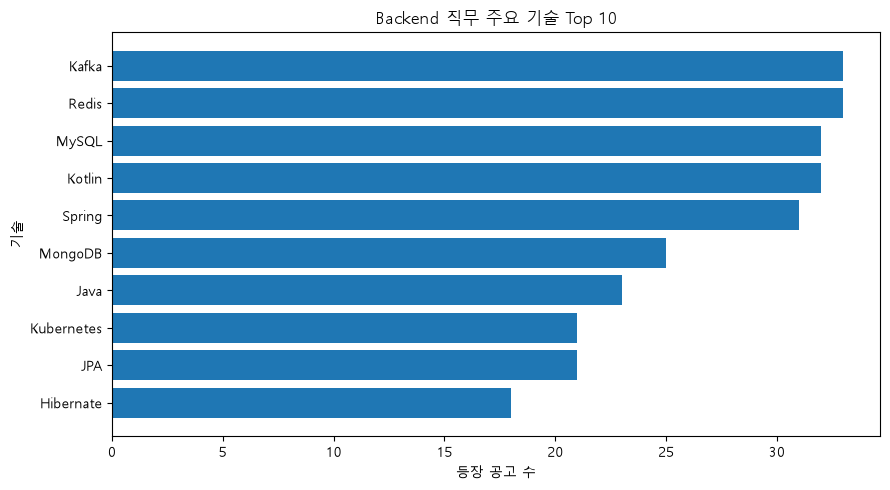

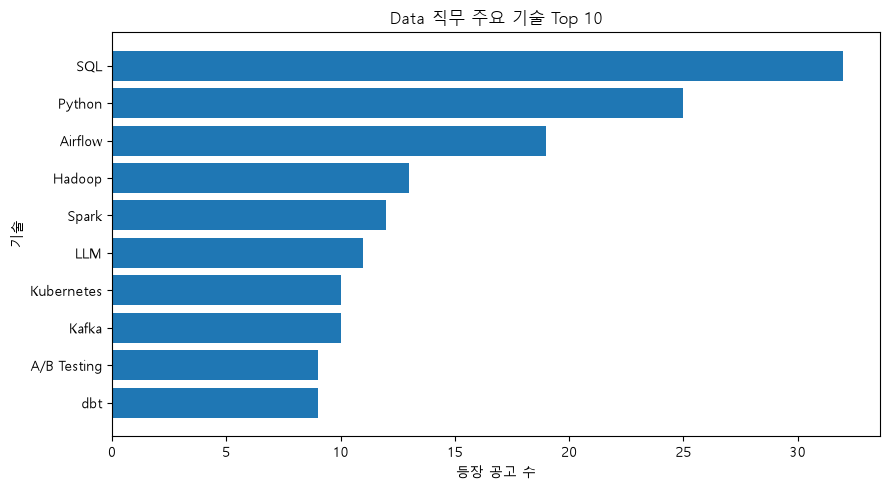

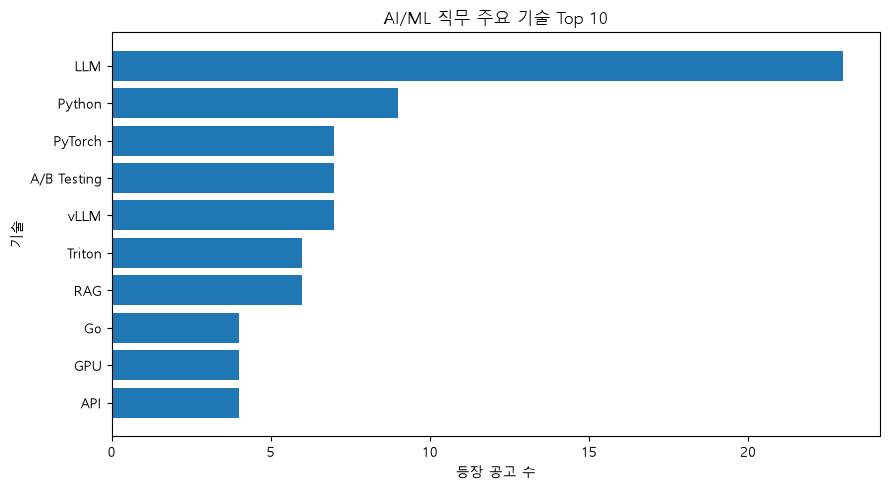

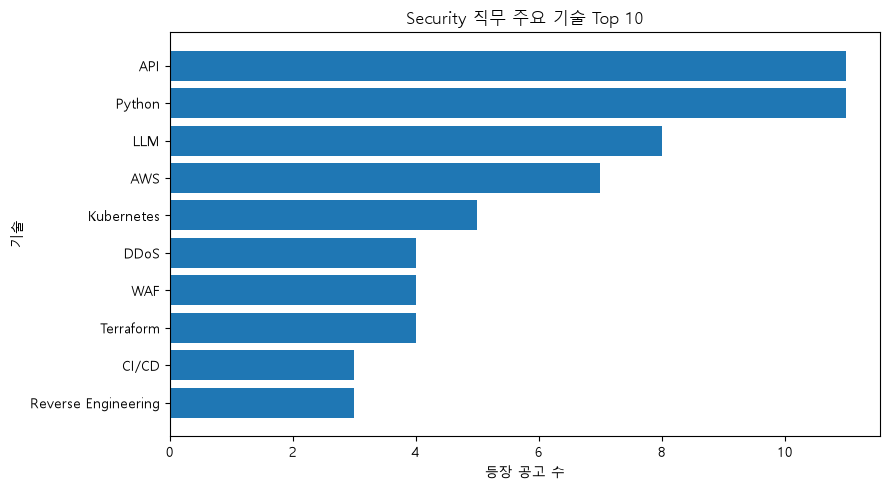

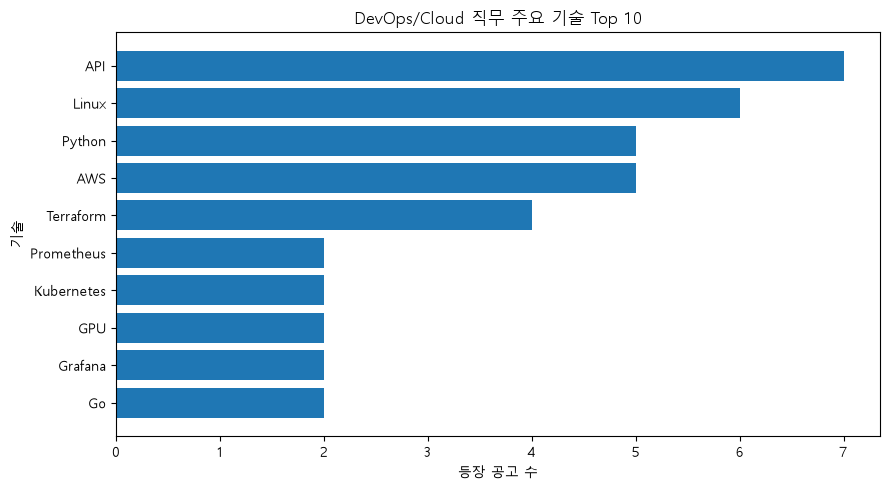

In [9]:
# --------------------------------------------------
# 주요 직무별 Top 10 기술 시각화
# --------------------------------------------------

major_categories = [
    "Backend",
    "Data",
    "AI/ML",
    "Security",
    "DevOps/Cloud",
]

for category in major_categories:
    plot_df = (
        category_top10_df[
            category_top10_df["job_category_std"]
            == category
        ]
        .sort_values("count")
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        plot_df["skill"],
        plot_df["count"]
    )

    plt.title(
        f"{category} 직무 주요 기술 Top 10"
    )
    plt.xlabel("등장 공고 수")
    plt.ylabel("기술")

    plt.tight_layout()
    plt.show()

In [10]:
# --------------------------------------------------
# 직무별 기술 등장 비율 계산
# --------------------------------------------------

category_job_counts = (
    jobs_df["job_category_std"]
    .value_counts()
    .to_dict()
)

category_skill_ratio_df = (
    category_skill_counts
    .copy()
)

category_skill_ratio_df["job_count"] = (
    category_skill_ratio_df[
        "job_category_std"
    ]
    .map(category_job_counts)
)

category_skill_ratio_df["ratio"] = (
    category_skill_ratio_df["count"]
    / category_skill_ratio_df["job_count"]
)

category_skill_ratio_df["ratio_percent"] = (
    category_skill_ratio_df["ratio"] * 100
)

category_ratio_top10_df = (
    category_skill_ratio_df
    .sort_values(
        [
            "job_category_std",
            "ratio",
            "count",
            "skill",
        ],
        ascending=[
            True,
            False,
            False,
            True,
        ]
    )
    .groupby(
        "job_category_std",
        group_keys=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(
    category_ratio_top10_df[
        [
            "job_category_std",
            "skill",
            "count",
            "job_count",
            "ratio_percent",
        ]
    ]
)

,job_category_std,skill,count,job_count,ratio_percent
0,AI/ML,LLM,23,37,62.162162
1,AI/ML,Python,9,37,24.324324
2,AI/ML,A/B Testing,7,37,18.918919
3,AI/ML,PyTorch,7,37,18.918919
4,AI/ML,vLLM,7,37,18.918919
...,...,...,...,...,...
64,Security,DDoS,4,24,16.666667
65,Security,Terraform,4,24,16.666667
66,Security,WAF,4,24,16.666667
67,Security,CI/CD,3,24,12.500000


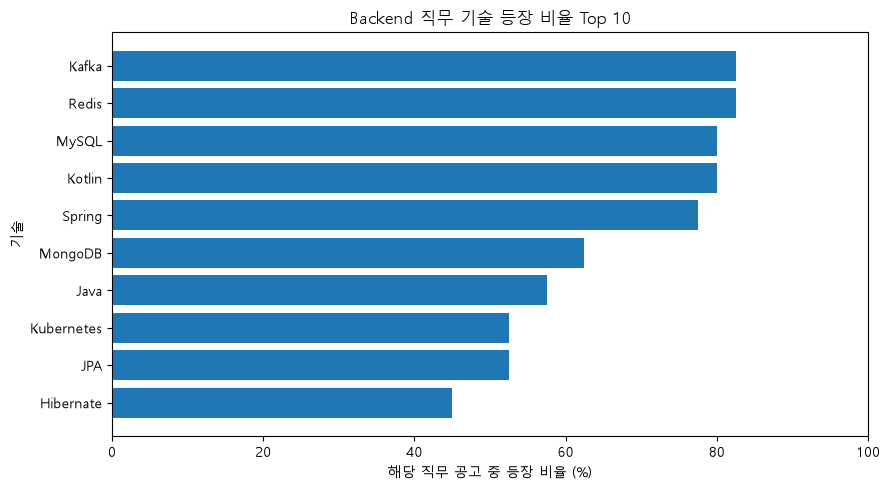

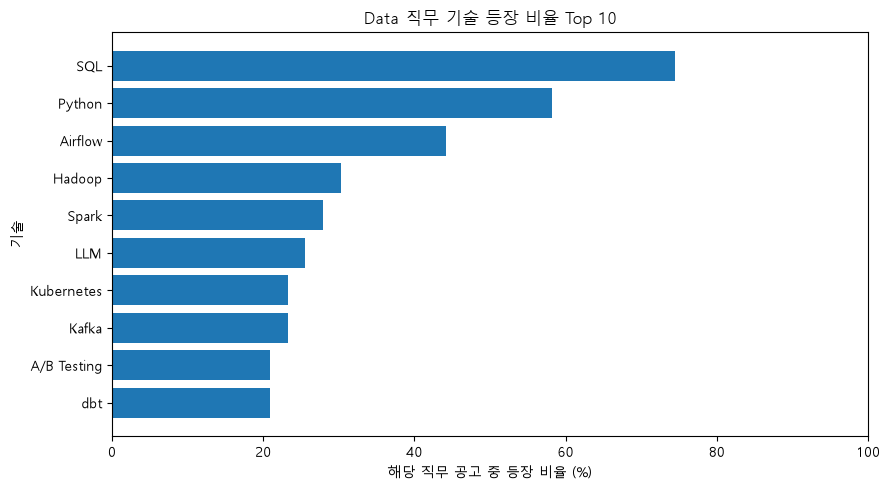

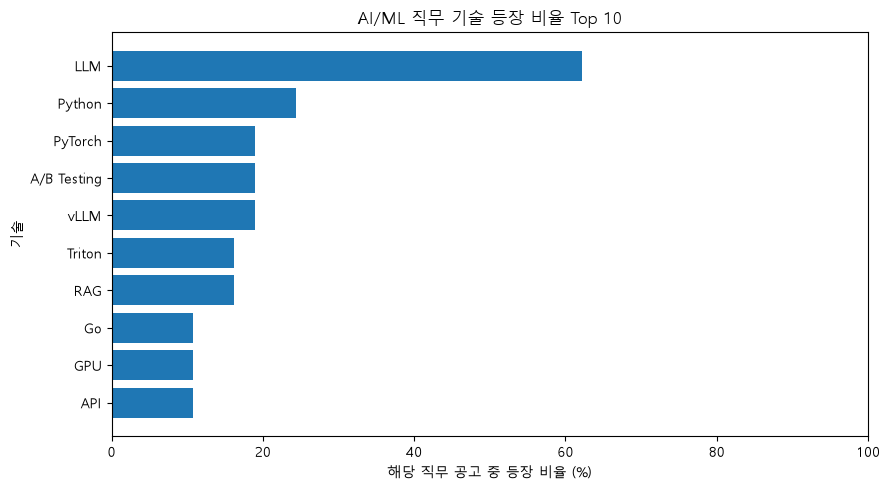

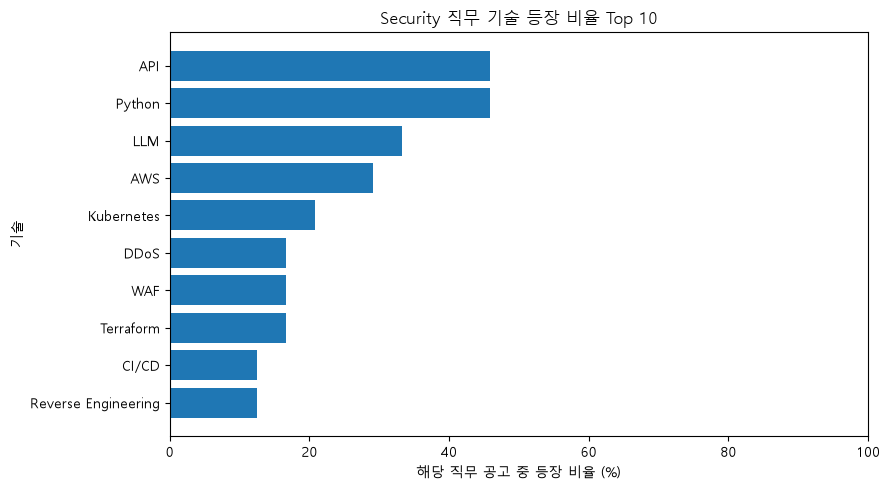

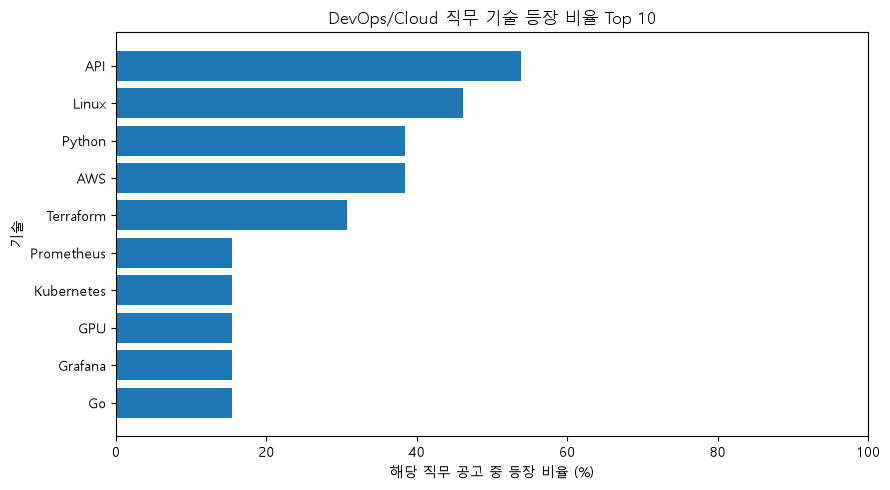

In [11]:
# --------------------------------------------------
# 주요 직무별 기술 등장 비율 Top 10
# --------------------------------------------------

major_categories = [
    "Backend",
    "Data",
    "AI/ML",
    "Security",
    "DevOps/Cloud",
]

for category in major_categories:
    plot_df = (
        category_ratio_top10_df[
            category_ratio_top10_df[
                "job_category_std"
            ] == category
        ]
        .sort_values("ratio_percent")
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        plot_df["skill"],
        plot_df["ratio_percent"]
    )

    plt.title(
        f"{category} 직무 기술 등장 비율 Top 10"
    )
    plt.xlabel("해당 직무 공고 중 등장 비율 (%)")
    plt.ylabel("기술")

    plt.xlim(0, 100)

    plt.tight_layout()
    plt.show()

In [12]:
# --------------------------------------------------
# 기업별 기술스택 분석용 데이터 생성
# --------------------------------------------------

MIN_COMPANY_JOBS = 8

company_job_counts = (
    jobs_df["company"]
    .value_counts()
)

analysis_companies = (
    company_job_counts[
        company_job_counts >= MIN_COMPANY_JOBS
    ]
    .index
    .tolist()
)

print(
    "분석 대상 기업:",
    analysis_companies
)

company_skill_rows = []

for _, row in jobs_df.iterrows():
    company = row["company"]

    if company not in analysis_companies:
        continue

    if pd.isna(row["skills_std_clean"]):
        continue

    skills = {
        skill.strip()
        for skill in str(
            row["skills_std_clean"]
        ).split("|")
        if skill.strip()
    }

    for skill in skills:
        company_skill_rows.append(
            {
                "company": company,
                "skill": skill,
            }
        )

company_skill_df = pd.DataFrame(
    company_skill_rows
)

company_skill_counts = (
    company_skill_df
    .groupby(
        ["company", "skill"]
    )
    .size()
    .reset_index(
        name="count"
    )
)

display(company_skill_counts.head())

분석 대상 기업: ['토스', '토스증권', '토스뱅크', '토스플레이스', '카카오', '토스페이먼츠']


,company,skill,count
0,카카오,AWQ,1
1,카카오,Airflow,1
2,카카오,Bi-Encoder,1
3,카카오,C++,1
4,카카오,CI/CD,1


In [13]:
# --------------------------------------------------
# 기업별 기술 등장 비율 계산
# --------------------------------------------------

company_count_map = (
    jobs_df[
        jobs_df["company"].isin(
            analysis_companies
        )
    ]["company"]
    .value_counts()
    .to_dict()
)

company_skill_ratio_df = (
    company_skill_counts.copy()
)

company_skill_ratio_df["job_count"] = (
    company_skill_ratio_df["company"]
    .map(company_count_map)
)

company_skill_ratio_df["ratio_percent"] = (
    company_skill_ratio_df["count"]
    / company_skill_ratio_df["job_count"]
    * 100
)

company_top10_df = (
    company_skill_ratio_df
    .sort_values(
        [
            "company",
            "ratio_percent",
            "count",
            "skill",
        ],
        ascending=[
            True,
            False,
            False,
            True,
        ]
    )
    .groupby(
        "company",
        group_keys=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(
    company_top10_df[
        [
            "company",
            "skill",
            "count",
            "job_count",
            "ratio_percent",
        ]
    ]
)

,company,skill,count,job_count,ratio_percent
0,카카오,LLM,6,8,75.000000
1,카카오,Python,5,8,62.500000
2,카카오,PyTorch,4,8,50.000000
3,카카오,CUDA,2,8,25.000000
4,카카오,FP8,2,8,25.000000
5,카카오,Knowledge Distillation,2,8,25.000000
6,카카오,AWQ,1,8,12.500000
7,카카오,Airflow,1,8,12.500000
8,카카오,Bi-Encoder,1,8,12.500000
9,카카오,C++,1,8,12.500000


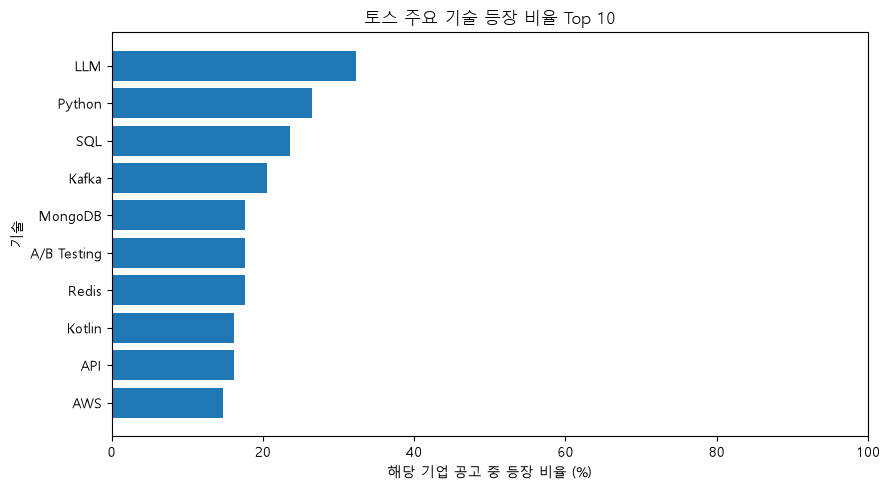

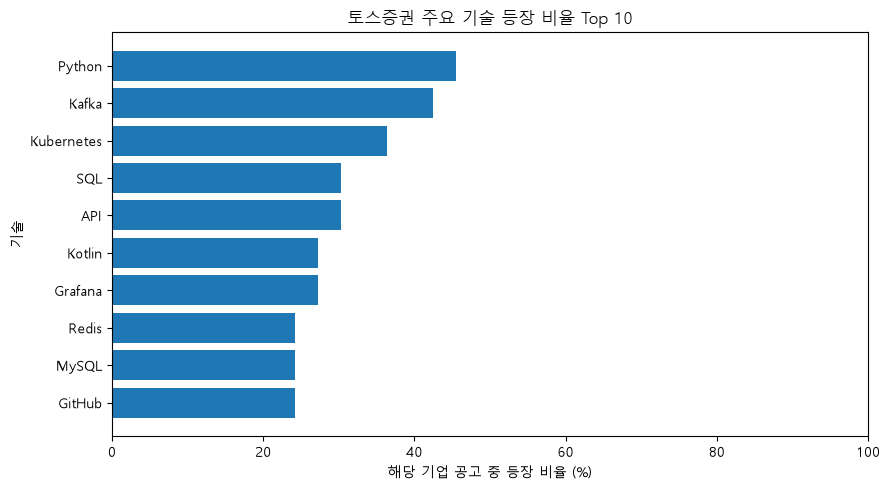

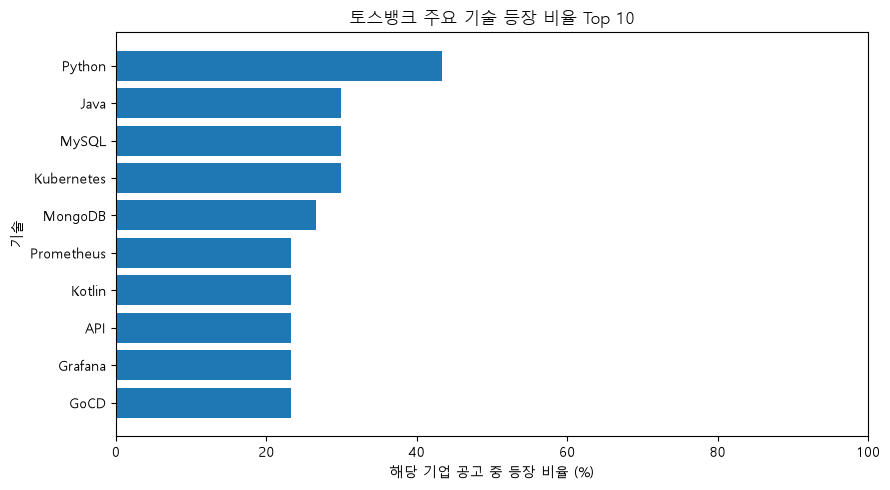

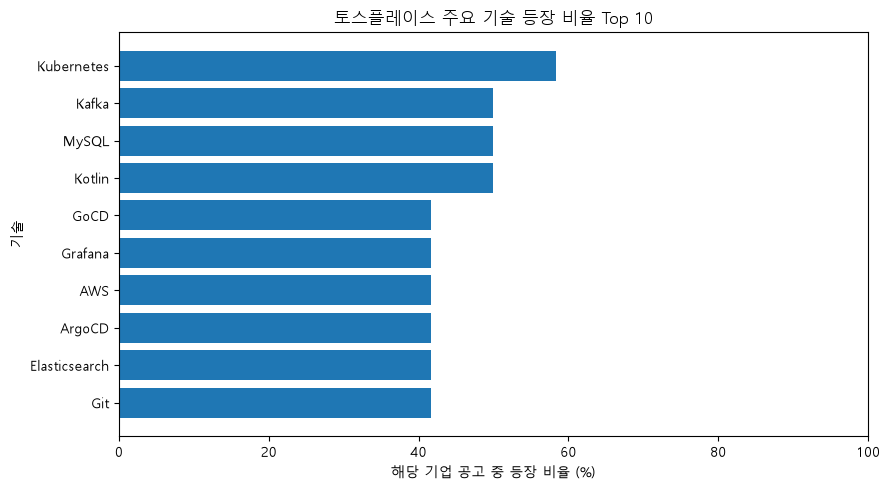

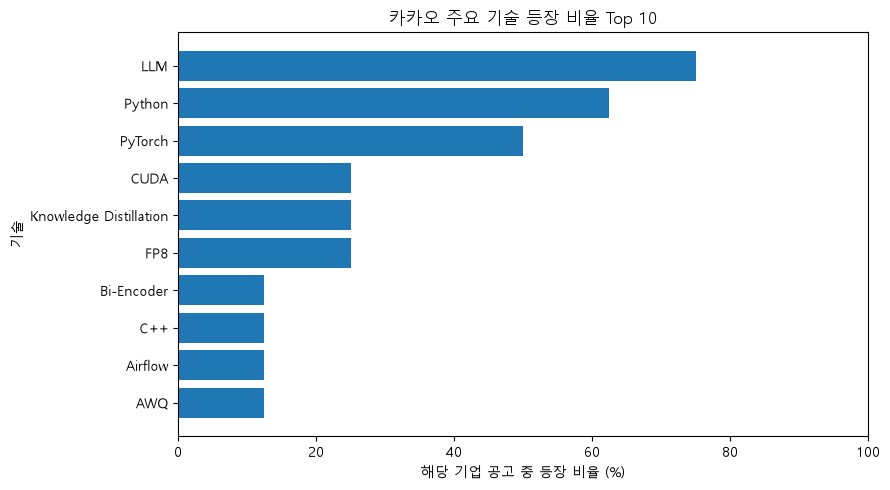

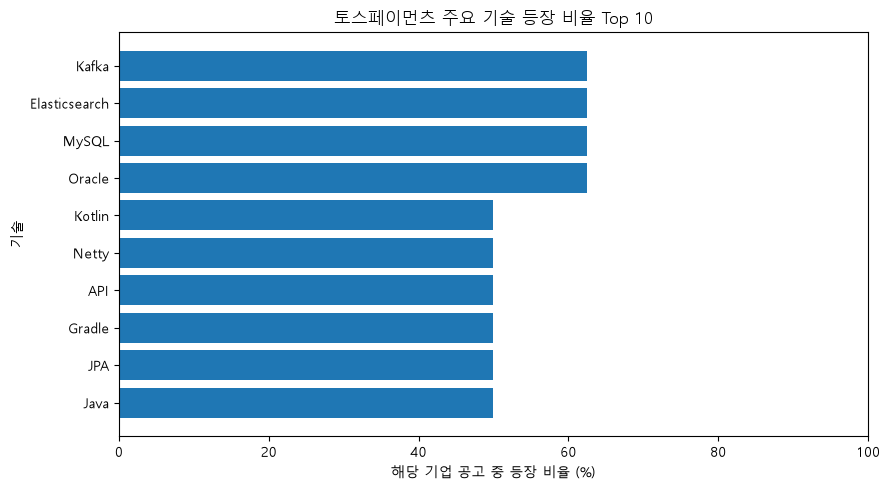

In [14]:
# --------------------------------------------------
# 기업별 주요 기술 등장 비율 Top 10
# --------------------------------------------------

for company in analysis_companies:
    plot_df = (
        company_top10_df[
            company_top10_df["company"]
            == company
        ]
        .sort_values("ratio_percent")
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        plot_df["skill"],
        plot_df["ratio_percent"]
    )

    plt.title(
        f"{company} 주요 기술 등장 비율 Top 10"
    )
    plt.xlabel("해당 기업 공고 중 등장 비율 (%)")
    plt.ylabel("기술")

    plt.xlim(0, 100)

    plt.tight_layout()
    plt.show()

In [15]:
# --------------------------------------------------
# Required / Preferred 비교 가능 여부 점검
# --------------------------------------------------

required_available = (
    jobs_df["requirements"]
    .notna()
    .sum()
)

preferred_available = (
    jobs_df["preferred"]
    .notna()
    .sum()
)

total_jobs = len(jobs_df)

print(
    "전체 공고:",
    total_jobs
)

print(
    "requirements 존재:",
    required_available,
    f"({required_available / total_jobs * 100:.1f}%)"
)

print(
    "preferred 존재:",
    preferred_available,
    f"({preferred_available / total_jobs * 100:.1f}%)"
)

print(
    "requirements + preferred 모두 존재:",
    (
        jobs_df["requirements"].notna()
        & jobs_df["preferred"].notna()
    ).sum()
)# --------------------------------------------------
# Required / Preferred 비교 가능 여부 점검
# --------------------------------------------------

required_available = (
    jobs_df["requirements"]
    .notna()
    .sum()
)

preferred_available = (
    jobs_df["preferred"]
    .notna()
    .sum()
)

total_jobs = len(jobs_df)

print(
    "전체 공고:",
    total_jobs
)

print(
    "requirements 존재:",
    required_available,
    f"({required_available / total_jobs * 100:.1f}%)"
)

print(
    "preferred 존재:",
    preferred_available,
    f"({preferred_available / total_jobs * 100:.1f}%)"
)

print(
    "requirements + preferred 모두 존재:",
    (
        jobs_df["requirements"].notna()
        & jobs_df["preferred"].notna()
    ).sum()
)

전체 공고: 168
requirements 존재: 167 (99.4%)
preferred 존재: 78 (46.4%)
requirements + preferred 모두 존재: 78
전체 공고: 168
requirements 존재: 167 (99.4%)
preferred 존재: 78 (46.4%)
requirements + preferred 모두 존재: 78


In [16]:
import re

# --------------------------------------------------
# Required / Preferred 내 기술 추출
# - 부분 문자열 오탐 방지
# - 긴 기술명 우선
# - 중첩 매칭 방지
# --------------------------------------------------

valid_skills = (
    skill_dict_df.loc[
        skill_dict_df["keep"] == True,
        "standard_skill"
    ]
    .dropna()
    .drop_duplicates()
    .tolist()
)

# Spring Boot → Spring 순으로 검사되도록
valid_skills = sorted(
    valid_skills,
    key=len,
    reverse=True
)


def extract_skills_from_text(text):
    if pd.isna(text):
        return []

    text = str(text)

    found = []
    occupied_spans = []

    for skill in valid_skills:
        escaped_skill = re.escape(
            str(skill)
        )

        # 영문/숫자 단어 내부에서 잘못 잡히는 것 방지
        pattern = re.compile(
            rf"(?<![A-Za-z0-9])"
            rf"{escaped_skill}"
            rf"(?![A-Za-z0-9])",
            flags=re.IGNORECASE,
        )

        for match in pattern.finditer(text):
            start, end = match.span()

            # 이미 더 긴 기술명이 차지한 영역이면 제외
            overlap = any(
                start < existing_end
                and end > existing_start
                for existing_start, existing_end
                in occupied_spans
            )

            if overlap:
                continue

            found.append(skill)
            occupied_spans.append(
                (start, end)
            )

            # 한 공고의 한 필드에서는 같은 기술 1회만
            break

    return found


jobs_df["required_skills_eda"] = (
    jobs_df["requirements"]
    .apply(extract_skills_from_text)
)

jobs_df["preferred_skills_eda"] = (
    jobs_df["preferred"]
    .apply(extract_skills_from_text)
)

print(
    "Required에서 기술 1개 이상 추출된 공고:",
    jobs_df["required_skills_eda"]
    .apply(len)
    .gt(0)
    .sum()
)

print(
    "Preferred에서 기술 1개 이상 추출된 공고:",
    jobs_df["preferred_skills_eda"]
    .apply(len)
    .gt(0)
    .sum()
)

display(
    jobs_df[
        [
            "company",
            "title",
            "required_skills_eda",
            "preferred_skills_eda",
        ]
    ].head(20)
)

Required에서 기술 1개 이상 추출된 공고: 133
Preferred에서 기술 1개 이상 추출된 공고: 65


,company,title,required_skills_eda,preferred_skills_eda
0,NAVER WEBTOON,[2027 상반기 채용연계형 인턴십] 네이버웹툰 백엔드 서버 개발 (Backend ...,"[Spring Boot, REST API, Kotlin, Java, HTTP, SQ...",[]
1,SNOW,[SNOW] IT 보안 기술 담당,"[DLP, EDR]","[SIEM, LLM, API, DLP, EDR]"
2,SNOW,[SNOW] 클라우드 보안 담당,"[SIEM, AWS]","[Cloud Security, AWS]"
3,NAVER WEBTOON,[네이버웹툰] Jr. IT Ops Engineer (경력),[],[API]
4,카카오,Multimodal LLM Research Engineer (경력),"[PyTorch, Python]",[LLM]
5,카카오,Data Scientist (경력),"[scikit-learn, PyTorch, Python, Hadoop, Spark,...","[Airflow, Docker, LLM]"
6,카카오,AI Platform 추론 최적화 Engineer(경력),"[TensorRT-LLM, Transformer, PyTorch, Python, S...","[NVIDIA Triton Inference Server, FlashAttentio..."
7,카카오,AI Research Engineer (Search & Agent) (경력),"[Policy Optimization, Negative Sampling, Embed...","[Knowledge Distillation, Information Retrieval..."
8,카카오,Data Analytics Engineer (경력),"[Airflow, Python, Impala, Trino, Hive, SQL]",[Hadoop]
9,카카오,생성형 모델 Research Engineer (Post-training) (신입/경력),"[PyTorch, Python]",[GPU]


In [17]:
# --------------------------------------------------
# 짧은 기술명 오탐 여부 점검
# --------------------------------------------------

short_skills = {
    "C",
    "R",
    "Go",
}

short_skill_check = jobs_df[
    jobs_df["required_skills_eda"].apply(
        lambda skills: any(
            skill in short_skills
            for skill in skills
        )
    )
    | jobs_df["preferred_skills_eda"].apply(
        lambda skills: any(
            skill in short_skills
            for skill in skills
        )
    )
][
    [
        "company",
        "title",
        "required_skills_eda",
        "preferred_skills_eda",
    ]
]

print(
    "짧은 기술명이 추출된 공고:",
    len(short_skill_check)
)

display(short_skill_check)

짧은 기술명이 추출된 공고: 12


,company,title,required_skills_eda,preferred_skills_eda
6,카카오,AI Platform 추론 최적화 Engineer(경력),"[TensorRT-LLM, Transformer, PyTorch, Python, S...","[NVIDIA Triton Inference Server, FlashAttentio..."
20,토스,AI 플랫폼 엔지니어 (Infra) (AI Platform Engineer),"[Kubernetes, Python, SGLang, vLLM, LLM, GPU, Go]","[NCCL, RDMA, RoCE, GPU]"
25,토스,AI 플랫폼 엔지니어 (Inference Pipeline) (AI Platform ...,"[LLM, API, Go]","[LLM, API]"
39,토스뱅크,ML 백엔드 엔지니어 (ML Backend Engineer),"[Python, Kotlin, Go]",[]
71,토스페이먼츠,서버 개발자 (TCP·전문통신) (Server Developer),[],"[Kotlin, Spring, Netty, Java, JPA, C]"
83,토스증권,서버 개발자 (Market Platform) (Server Developer),"[Spring Framework, Kotlin, Go]",[]
84,토스증권,서버 개발자 (FEP) (Server Developer),"[Kotlin, Oracle, Docker, Kafka, Git, Go, S3, C]",[]
88,토스,네트워크 소프트웨어 엔지니어 (Network Software Engineer),[Go],[Go]
131,토스,보안 리서처 (모바일보안) (Security Researcher),"[Android, Python, Kotlin, Swift, Java, iOS, C+...",[]
142,토스증권,Security Engineer (보안 인프라),"[Kubernetes, Terraform, Python, ZTNA, eBPF, AW...",[]


In [18]:
# --------------------------------------------------
# 짧은 기술명 실제 문맥 확인
# --------------------------------------------------

short_skill_context_df = jobs_df[
    jobs_df.index.isin(short_skill_check.index)
][
    [
        "job_id",
        "company",
        "title",
        "requirements",
        "preferred",
        "required_skills_eda",
        "preferred_skills_eda",
    ]
]

pd.set_option(
    "display.max_colwidth",
    None
)

display(short_skill_context_df)

,job_id,company,title,requirements,preferred,required_skills_eda,preferred_skills_eda
6,kakao_P-14469,카카오,AI Platform 추론 최적화 Engineer(경력),"- Python 또는 Go을 활용한 시스템/백엔드/ML 시스템 개발 경력이 5년 이상인 분 - Transformer 아키텍처 및 LLM 동작 원리(어텐션, KV cache, 디코딩 전략 등)에 대한 깊은 이해가 있는 분 - vLLM, SGLang, TensorRT-LLM, TGI 중 하나 이상을 실제 프로덕션 또는 대규모 실험 환경에서 운영해 본 경험이 있는 분 - GPU 환경에서의 성능 프로파일링 및 최적화 경험이 있는 분 (Nsight, NCU, PyTorch Profiler 등) - K8s에 대한 이해도가 높은 분 - 클라우드 환경에서의 CI/CD 경험이 있는 분 - 새로운 환경에 도전하는 오픈 마인드를 가진 분","- vLLM, SGLang, TensorRT-LLM, Hugging Face Transformers, PyTorch 등 LLM/ML 오픈소스 프로젝트에 의미 있는 컨트리뷰션 경험이 있는 분 (PR 머지, RFC 작성, 메인테이너 활동, 이슈 트리아지 등) - CUDA / Triton 커널을 직접 작성하거나 튜닝해 본 경험이 있는 분 - LLM 추론 가속 기법(Speculative Decoding, Mixture-of-Experts, FlashAttention, PagedAttention, RadixAttention 등)을 실무에 적용해 본 경험이 있는 분 - 모델 양자화 / 압축 (AWQ, GPTQ, FP8, INT4, SmoothQuant, Pruning, Distillation 등) 실무 경험이 있는 분 - 대규모 분산 추론(Tensor / Pipeline / Expert Parallelism, Disaggregated Prefill-Decode 등)을 설계·운영해 본 경험이 있는 분 - NVIDIA Triton Inference Server, KServe, Ray Serve, vLLM Production Stack, LLM-D 등 서빙 플랫폼 구축 경험이 있는 분 - 대규모 GPU 클러스터(수십~수백 GPU 이상) 환경에서의 추론 워크로드 운영 경험이 있는 분 - 고성능 네트워킹(RDMA, RoCE, InfiniBand, NCCL 튜닝) 또는 네트워크 트러블 슈팅 경험이 있는 분 - ML 또는 AI 동작에 대한 이해도가 높은 분 - 다양한 프로그래밍 언어 사용에 대한 거부감이 없는 분 (Python / C++ / CUDA / Go / Rust 등) - LLM 추론 성능 관련 논문을 읽고 구현/재현해 본 경험이 있는 분","[TensorRT-LLM, Transformer, PyTorch, Python, SGLang, CI/CD, Cache, vLLM, LLM, GPU, TGI, Go]","[NVIDIA Triton Inference Server, FlashAttention, PagedAttention, RadixAttention, Transformers, Hugging Face, TensorRT-LLM, SmoothQuant, InfiniBand, Ray Serve, PyTorch, Python, Triton, KServe, SGLang, vLLM, CUDA, GPTQ, INT4, NCCL, RDMA, RoCE, Rust, LLM, GPU, C++, FP8, AWQ, Go]"
20,toss_8007436003,토스,AI 플랫폼 엔지니어 (Infra) (AI Platform Engineer),"- 5년 이상 또는 그에 준하는 인프라 역량으로, Kubernetes 기반의 공용 플랫폼을 직접 설계하고 운영해 본 분과 함께하고 싶어요.\r\n- 대규모 GPU 클러스터 및 GPU Operator 스택 프로덕션 운영 경험이 있는 분과 함께하고 싶어요\r\n- vLLM, SGLang 등 LLM 서빙 엔진을 활용한 대용량 트래픽 처리 및 분산 추론 인프라의 프로덕션 운영 을 해본 분과 함께하고 싶어요\r\n- Python, Go 등을 활용한 인프라 자동화, 또는 K8s CRD/Controller 패턴을 직접 구현해 시스템을 구조적으로 추상화해 본 분이면 좋아요\r\n- AI/ML 모델링에 대한 완벽한 도메인 지식이 없어도 괜찮아요. 탄탄한 K8s 역량과 인프라 최적화 경험을 바탕으로, 데이터 및 AI 조직과 협업하며 토스의 압도적인 LLM 시스템 생태계를 함께 고도화해 나갈 수 있으면 충분해요.","- NVIDIA Dynamo 등 분산 추론 아키텍처나 RDMA(IB/RoCE), NCCL 기반의 고속 GPU 네트워크 환경을 이해하고 계신 분이면 잘 맞아요.\r\n- Volcano, Kueue 등을 활용해 대규모 멀티테넌트 GPU 자원을 스케줄링해 보셨으면 더욱 환영해요.\r\n- 온프레미스와 퍼블릭 클라우드가 결합된 하이브리드 환경, 혹은 VAST 등 고성능 AI 스토리지를 다뤄본 경험이 있으시면 더욱 좋아요.\r\n- 단순 운영을 넘어 DCGM 지표, XID, NVLink 등 GPU 하드웨어 레벨의 장애를 깊이 있게 분석하고 진단해 본 분이면 ML/AI Infra 팀의 방향과 완벽하게 잘 맞을 거예요.","[Kubernetes, Python, SGLang, vLLM, LLM, GPU, Go]","[NCCL, RDMA, RoCE, GPU]"
25,toss_7986152003,토스,AI 플랫폼 엔지니어 (Inference Pipeline) (AI Platform Engineer),"- LLM이나 ML 모델을 활용한 수천만 건 규모의 대용량 데이터 처리 파이프라인을 라이브 서비스 수준으로 설계하고 운영해본 경험이 있는 분과 함께하고 싶어요.\r\n- 요청과 결과를 분리한 비동기 구조나 대량 배치 처리로 대규모 트래픽을 다뤄본 경험이 있는 분이면 좋아요.\r\n- LLM 생태계를 이해하고, Pay-as-you-go, PTU, Batch API의 트레이드오프를 비용과 처리량 관점에서 판단할 수 있는 분이면 좋아요.\r\n- Rate Limit과 이중화, 장애 전환, Fallback/Retry를 직접 설계해 장애 상황에서도 파이프라인이 멈추지 않게 만들어본 분과 함께하고 싶어요.\r\n- 처리량이 기대만큼 나오지 않을 때 어느 구간이 문제인지 숫자로 찾아내고, 무엇을 포기할지까지 정해본 분과 함께하고 싶어요.\r\n- 여러 팀이 얽힌 상황에서 기술 판단 기준을 제시하고, 복잡한 내용을 이해하기 쉽게 설명하며 협업을 이끌어본 분과 함께하고 싶어요.","- 이미지와 텍스트가 함께 들어오는 멀티모달 파이프라인을 설계하고 운영해본 경험이 있다면 좋아요.\r\n- ML, LLM, Vision 모델의 동작 방식을 이해하고, 문제가 생겼을 때 직접 디버깅해 모델 코드까지 고칠 수 있다면 좋아요.\r\n- 사람이 하던 대량의 판단 업무를 LLM으로 자동화해본 경험이 있다면 특히 함께하고 싶어요.\r\n- 외부 모델 API와 함께 자체 모델을 서빙하면서, 추론 성능을 최적화해본 경험이 있다면 환영해요.","[LLM, API, Go]","[LLM, API]"
39,toss_6600650003,토스뱅크,ML 백엔드 엔지니어 (ML Backend Engineer),"- Python, Kotlin, Go 등 하나 이상의 언어로 서버를 개발하고 운영해 본 경험이 필요해요.\r\n- 견고한 서비스 아키텍처를 설계하고 안정적인 구조의 코드를 구현할 수 있는 역량이 필요해요.\r\n- 쿠버네티스 환경 위에서 서버를 배포하고 모니터링하며 안정적으로 운영한 경험이 있으면 좋아요.\r\n- 대규모 트래픽을 받거나 SLA가 높은 서비스를 프로덕션으로 개발하고 운영한 경험과 역량이 있으면 좋아요.\r\n- 크고 복잡한 문제를 소프트웨어 기술로 해결하거나, 혹은 서비스나 제품으로 비즈니스 임팩트를 낸 경험이 있으면 좋아요.\r\n- ML 경험은 없어도 좋아요. AI/ML 분야에 관심이 많고 이 방향으로의 경험을 쌓고 싶은 분이면 좋아요.",NaN,"[Python, Kotlin, Go]",[]
71,toss_798005400

In [19]:
# --------------------------------------------------
# C 기술 추출 공고 문맥 확인
# --------------------------------------------------

c_skill_check = jobs_df[
    jobs_df["required_skills_eda"].apply(
        lambda skills: "C" in skills
    )
    | jobs_df["preferred_skills_eda"].apply(
        lambda skills: "C" in skills
    )
][
    [
        "job_id",
        "company",
        "title",
        "requirements",
        "preferred",
        "required_skills_eda",
        "preferred_skills_eda",
    ]
]

print(
    "C가 추출된 공고:",
    len(c_skill_check)
)

display(c_skill_check)

C가 추출된 공고: 3


,job_id,company,title,requirements,preferred,required_skills_eda,preferred_skills_eda
71,toss_7980054003,토스페이먼츠,서버 개발자 (TCP·전문통신) (Server Developer),"- TCP/IP 프로그래밍과 트러블슈팅 경험이 있는 경력 8년 이상의 분을 찾아요.\r\n- 복잡한 기술 제품을 운영하고 개발 과제를 리딩한 경험이 있는 분을 찾아요.\r\n- 단순히 개발 과제를 수행하는 수준에 그치지 않고, 차세대 통합전문처리 시스템 개발을 이끌며 다양한 이해관계자(기획/디자인/개발/운영/CX/원천사 등)분들과 함께 더 강한 팀을 만들어 가는 분과 함께하고 싶어요.\r\n- 다른 분야의 전문가들에게도 친절하고 명쾌하게 설명할 수 있는 커뮤니케이션 역량을 갖춘 분과 함께하고 싶어요.\r\n- 동료에게 필요한 지식을 전파하고, 협업을 즐기는 분을 찾아요.\r\n- 레거시를 재설계하는 데 거부감이 없고 오히려 즐기는 분을 찾아요.","- C·Kotlin·Spring·JPA 등 Java 기술 생태계에 대한 이해와 OOP·TDD·리팩터링·페어 프로그래밍 같은 엔지니어링 역량을 갖추고 있다면 더 좋아요.\r\n- 레거시 시스템을 개선해본 경험이 있다면 더 좋아요.\r\n- 대용량 시스템을 개발·운영해본 경험이 있다면 더 좋아요.\r\n- 비동기 네트워크 프로그래밍 경험이 있거나 이에 대한 이해도가 있다면 더 좋아요.\r\n- Netty, Golang 등을 사용해본 경험이 있다면 더 좋아요.\r\n- 결제 관련 개발 경험이 있다면 더 좋아요.",[],"[Kotlin, Spring, Netty, Java, JPA, C]"
84,toss_5863983003,토스증권,서버 개발자 (FEP) (Server Developer),"☑️ **공통**\r\n- 리눅스 시스템에 대한 이해 및 각종 명령어, 쉘 환경에 대한 이해가 기본 전제가 되어 있어야 해요.\r\n- 주어진 스펙 문서 또는 기 구축된 시스템에 대해 분석하여 개발할 수 있어야 해요. \r\n- go 언어, C 언어, kotlin 등 언어에 대한 이해도가 높고, 다양한 개발 환경에 적응을 잘하시면 더 좋아요.\r\n\r\n☑️ **증권사 FEP 경력이 2년 이상 있는 경우**\r\n- FEP 시스템의 내부 설계 및 모든 기능들에 대해 이해하고 있어야 하며, 이슈 발생 시 빠르게 원인을 찾고 해결할 수 있는 역량이 필요해요.\r\n- FEP 시스템을 직접 설계하고 개발하실 수 있으면 더 좋아요.\r\n- FEP 운영 관련 서버/IP/스토리지 이중화 구성, DR 구성 및 전환훈련, 인증서 관리, 암복호화, 제도개편 대응, 성능튜닝, 데몬 프로세스 활용 등 운영성 업무에 대해 이해하고 있어야 해요.\r\n\r\n☑️ **증권사 FEP 경력이 없는 경우**\r\n- 다양한 환경(TCP, Oracle, Kafka, sftp, s3, git action, docker, nix, k8s 등)에서 개발하실 수 있어야 하고, 작은 이슈라도 명확히 해결하고 넘어가고, 모든 현상에 대해 깊이 있게 이해하는 습관이 있으면 좋아요. \r\n- 문제점에 대한 인식이나 개선방안에 대해 적극적으로 고민하고 트러블슈팅할 수 있는 문제해결자 성향이라면 더 좋아요. \r\n- TCP 네트워크 프로그래밍에 대해 이해하고 있고, 로우레벨 프로그래밍과 리눅스, docker 사용에 익숙해야 해요.\r\n- 컴퓨터 공학에 대한 높은 이해도와 탄탄한 기본기를 갖춘 분이면 더 좋아요.",NaN,"[Kotlin, Oracle, Docker, Kafka, Git, Go, S3, C]",[]
131,toss_7780944003,토스,보안 리서처 (모바일보안) (Security Researcher),"- Go, Python, Kotlin, Java, Swift, C/C++ 등 하나 이상의 언어로 필요한 도구나 시스템을 직접 개발해본 분과 함께하고 싶어요.\r\n- Android 또는 iOS 운영체제의 인터널, 네트워크, 웹/시스템의 동작 원리를 이해하고, 모바일 앱 리버스 엔지니어링이나 모바일 보안 취약점을 다뤄본 경험이 있는 분을 찾고 있어요.\r\n- 보안 점검을 수동으로 수행하는 데 그치지 않고, 빌드와 배포 과정에서 자동으로 검증되도록 만드는 일에 관심이 있는 분이면 좋아요.\r\n- 개별 취약점 하나를 찾는 것을 넘어, 같은 문제가 다시 생기지 않도록 플랫폼이나 시스템의 형태로 해결해본 분과 함께하고 싶어요.\r\n- 새로운 모바일 보안 기술과 OS 변화에 관심이 많고, 동료들과 함께 빠르게 학습하고 적용할 수 있는 분이면 좋아요.",NaN,"[Android, Python, Kotlin, Swift, Java, iOS, C++, Go, C]",[]


In [20]:
# --------------------------------------------------
# Required / Preferred 공정 비교용 표본
# 두 필드가 모두 존재하는 공고만 사용
# --------------------------------------------------

req_pref_df = jobs_df[
    jobs_df["requirements"].notna()
    & jobs_df["preferred"].notna()
].copy()

print(
    "Required / Preferred 비교 대상 공고:",
    len(req_pref_df)
)

Required / Preferred 비교 대상 공고: 78


In [21]:
# --------------------------------------------------
# Required / Preferred 기술 빈도 집계
# --------------------------------------------------

required_counter = Counter()
preferred_counter = Counter()

for skills in req_pref_df["required_skills_eda"]:
    required_counter.update(set(skills))

for skills in req_pref_df["preferred_skills_eda"]:
    preferred_counter.update(set(skills))


required_top_df = (
    pd.DataFrame(
        required_counter.items(),
        columns=["skill", "count"]
    )
    .sort_values(
        ["count", "skill"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

preferred_top_df = (
    pd.DataFrame(
        preferred_counter.items(),
        columns=["skill", "count"]
    )
    .sort_values(
        ["count", "skill"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

required_top_df["ratio_percent"] = (
    required_top_df["count"]
    / len(req_pref_df)
    * 100
)

preferred_top_df["ratio_percent"] = (
    preferred_top_df["count"]
    / len(req_pref_df)
    * 100
)

print("===== Required Top 20 =====")
display(required_top_df.head(20))

print("===== Preferred Top 20 =====")
display(preferred_top_df.head(20))

===== Required Top 20 =====


,skill,count,ratio_percent
0,Python,22,28.205128
1,SQL,15,19.230769
2,LLM,14,17.948718
3,Kubernetes,7,8.974359
4,Airflow,6,7.692308
5,Go,6,7.692308
6,PyTorch,6,7.692308
7,Spark,6,7.692308
8,API,5,6.410256
9,AWS,5,6.410256


===== Preferred Top 20 =====


,skill,count,ratio_percent
0,LLM,26,33.333333
1,API,12,15.384615
2,Java,9,11.538462
3,Kotlin,8,10.256410
4,AWS,7,8.974359
5,Kubernetes,7,8.974359
6,GPU,6,7.692308
7,Kafka,6,7.692308
8,Python,5,6.410256
9,Spring,5,6.410256


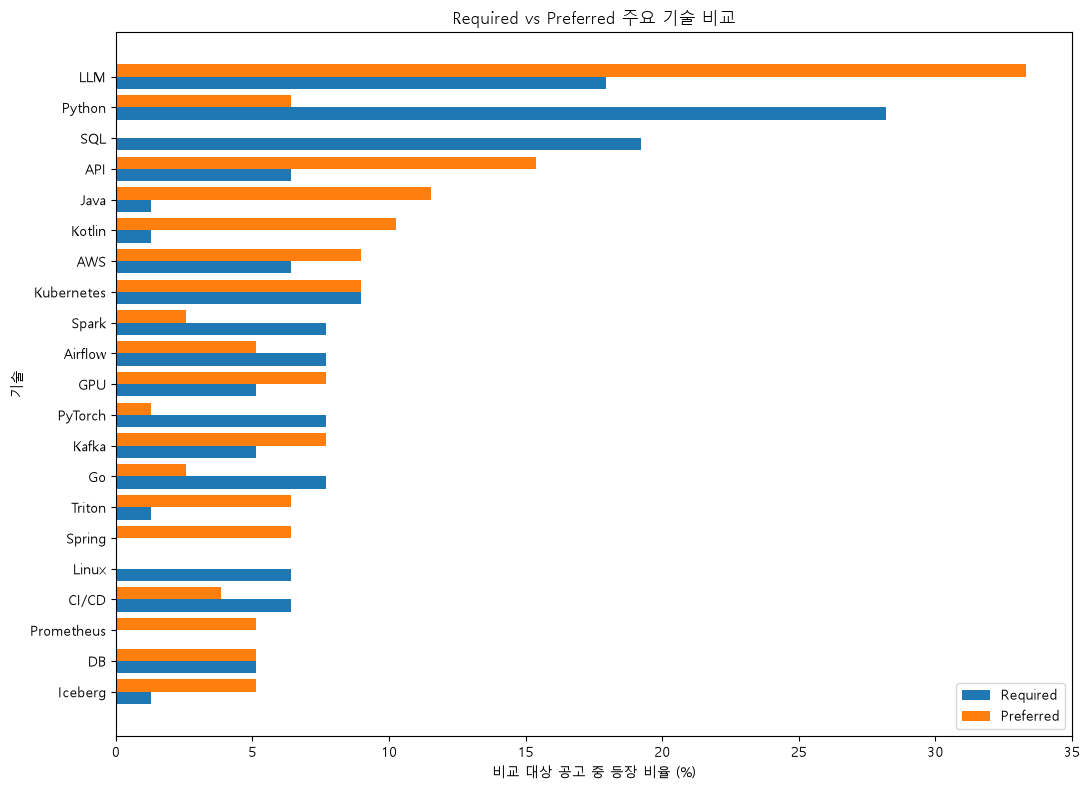

In [22]:
# --------------------------------------------------
# Required / Preferred Top 15 비교
# --------------------------------------------------

top_skills = (
    set(required_top_df.head(15)["skill"])
    | set(preferred_top_df.head(15)["skill"])
)

comparison_df = pd.DataFrame(
    {"skill": sorted(top_skills)}
)

comparison_df = comparison_df.merge(
    required_top_df[
        ["skill", "ratio_percent"]
    ].rename(
        columns={
            "ratio_percent":
            "required_percent"
        }
    ),
    on="skill",
    how="left",
)

comparison_df = comparison_df.merge(
    preferred_top_df[
        ["skill", "ratio_percent"]
    ].rename(
        columns={
            "ratio_percent":
            "preferred_percent"
        }
    ),
    on="skill",
    how="left",
)

comparison_df = (
    comparison_df
    .fillna(0)
)

comparison_df["max_percent"] = (
    comparison_df[
        [
            "required_percent",
            "preferred_percent",
        ]
    ]
    .max(axis=1)
)

comparison_df = (
    comparison_df
    .sort_values(
        "max_percent",
        ascending=True
    )
)

y = range(len(comparison_df))

plt.figure(figsize=(11, 8))

plt.barh(
    [i - 0.2 for i in y],
    comparison_df["required_percent"],
    height=0.4,
    label="Required",
)

plt.barh(
    [i + 0.2 for i in y],
    comparison_df["preferred_percent"],
    height=0.4,
    label="Preferred",
)

plt.yticks(
    list(y),
    comparison_df["skill"],
)

plt.xlabel("비교 대상 공고 중 등장 비율 (%)")
plt.ylabel("기술")
plt.title(
    "Required vs Preferred 주요 기술 비교"
)

plt.legend()
plt.tight_layout()
plt.show()

## EDA 핵심 인사이트

### 1. 데이터 구성
- 전체 채용공고: 168건
- 주요 직무 분포:
  - Data: 43건
  - Backend: 40건
  - AI/ML: 37건
  - Security: 24건
  - DevOps/Cloud: 13건
- Mobile 2건, Frontend 9건으로 일부 직무는 표본이 작아 해석에 주의가 필요하다.
- 기업별 데이터는 Toss 계열 비중이 높아 기업 비교 결과를 전체 채용시장으로 일반화하기 어렵다.

### 2. 전체 기술 수요
전체 채용공고에서 가장 많이 등장한 기술은 다음과 같다.

- Python: 54건
- Kafka: 48건
- LLM: 44건
- Kubernetes: 43건
- Kotlin: 40건
- MySQL: 40건
- API: 39건
- Redis: 36건
- SQL: 36건
- Spring: 34건

현재 수집 표본에서는 데이터, 백엔드, AI/ML, 인프라 관련 기술이 상위권에 함께 나타났다.

### 3. 직무별 기술 수요

#### Backend
Kafka, Redis, MySQL, Kotlin, Spring, Java, JPA, Hibernate 등이 높은 비율로 등장했다.

Backend 공고에서는 단순 프로그래밍 언어뿐 아니라 데이터베이스, 메시징, 프레임워크 및 인프라 기술을 함께 요구하는 경향이 나타났다.

#### Data
SQL, Python, Airflow, Hadoop, Spark 등이 주요 기술로 나타났다.

데이터 직무에서는 SQL과 Python을 중심으로 데이터 파이프라인 및 분산처리 기술이 함께 요구되는 경향이 확인되었다.

#### AI/ML
LLM이 가장 높은 비율로 나타났으며 Python, PyTorch, vLLM, Triton, RAG 등이 주요 기술로 확인되었다.

현재 AI/ML 채용공고에서는 전통적인 모델 개발뿐 아니라 LLM 및 모델 서빙·추론 기술 수요가 두드러졌다.

#### Security
API, Python, LLM, AWS, Kubernetes, DDoS, WAF, Reverse Engineering 등이 나타났다.

보안 직무에서도 클라우드·인프라·소프트웨어 개발 역량이 함께 요구되는 경향이 확인되었다.

#### DevOps/Cloud
API, Linux, Python, AWS, Terraform, Prometheus, Kubernetes, Grafana 등이 주요 기술로 나타났다.

인프라 자동화, 클라우드, 모니터링 및 운영 관련 기술이 핵심 역량으로 확인되었다.

### 4. 기업별 기술 특성
기업별 데이터 수가 크게 다르므로 기업 비교는 보조 분석으로 활용한다.

- 카카오: LLM, Python, PyTorch 등 AI/ML 기술 비중이 높음
- 토스: LLM, Python, SQL, Kafka 등 다양한 직무 기술이 혼합됨
- 토스증권: Python, Kafka, Kubernetes 중심
- 토스뱅크: Python, Java, Kubernetes, MySQL 중심
- 토스플레이스: Kubernetes, Kafka, Kotlin, MySQL 중심
- 토스페이먼츠: Kafka, Elasticsearch, MySQL, Oracle 등 백엔드·데이터 기술 비중이 높음

### 5. Required vs Preferred
requirements와 preferred가 모두 존재하는 78개 공고를 기준으로 비교하였다.

Required 상위 기술:
- Python: 28.2%
- SQL: 19.2%
- LLM: 17.9%
- Kubernetes: 9.0%
- Airflow / Go / PyTorch / Spark: 각각 7.7%

Preferred 상위 기술:
- LLM: 33.3%
- API: 15.4%
- Java: 11.5%
- Kotlin: 10.3%
- AWS / Kubernetes: 각각 9.0%

Python과 SQL은 Required에서 상대적으로 강하게 나타났으며, LLM은 Preferred에서 더 높은 비율을 보였다.

현재 수집 표본에서는 생성형 AI 관련 역량이 필수 조건뿐 아니라 우대·차별화 역량으로도 적극 활용되는 경향이 나타났다.

## 해석 시 주의사항
- 본 분석은 수집된 168개 채용공고 표본을 기반으로 한다.
- Toss 계열 공고 비중이 높으므로 전체 국내 채용시장을 대표한다고 해석하지 않는다.
- 기업별 분석은 기업 간 데이터 수 차이가 크므로 보조적인 참고 결과로 사용한다.
- Required / Preferred 비교는 두 필드가 모두 존재하는 78개 공고만 사용하였다.